In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# import os
# print(os.path.exists('/content/drive/MyDrive'))
# print(os.path.exists('/content/drive/MyDrive/ST5213py/datasets'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
True


In [1]:
# Lecture 11
# import packages
from scipy.stats import norm
from scipy.stats import chi2
from scipy.special import logit, expit
from statsmodels.api import MNLogit
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families import Poisson
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import os
# os.chdir('/content/drive/MyDrive/ST5213py/')
pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

In [2]:
# read table in the form of a contingency table
tab = pd.read_csv('dataset/vote.txt', sep=' ')
print(tab, '\n')

# Compute proportion of support for each party by sex
tab_subset = tab.iloc[:, 1:]  # exclude first column for sex
print(tab_subset.div(tab_subset.sum(axis=1), axis=0).round(3))

  Sex  CDU.CSU  SPD  FDP  Greens  PDS  Others
1   M      190  211   22      57   90      38
2   F      168  183   16      62  103      13 

   CDU.CSU    SPD    FDP  Greens    PDS  Others
1    0.312  0.347  0.036   0.094  0.148   0.062
2    0.308  0.336  0.029   0.114  0.189   0.024


In [3]:
# Convert to one row per (Sex, Party) with a count
df = tab.melt(id_vars='Sex', var_name='Party', value_name='count')
df['Party'] = pd.Categorical(df['Party'], categories=['SPD', 'CDU.CSU', 'FDP', 'Greens', 'PDS', 'Others'], ordered=True)
df['Sex'] = pd.Categorical(df['Sex'] )
print(df.head(), '\n')

# Expand to individual-level rows (1 row = 1 'voter')
df_long = df.loc[df.index.repeat(df['count'])].reset_index(drop=True)
df_long = df_long.drop(columns=['count'])
print(df_long.head())

  Sex    Party  count
0   M  CDU.CSU    190
1   F  CDU.CSU    168
2   M      SPD    211
3   F      SPD    183
4   M      FDP     22 

  Sex    Party
0   M  CDU.CSU
1   M  CDU.CSU
2   M  CDU.CSU
3   M  CDU.CSU
4   M  CDU.CSU


In [4]:
# Make Party categorical with SPD as baseline and create response vector
y = df_long['Party'].cat.codes
print(y, '\n')

# Create model matrix
X = patsy.dmatrix('Sex', df_long, return_type='dataframe')
print(X.head(),'\n')

# Fit multinomial logit model using data in long form
fm = MNLogit(y, X).fit()
print(fm.summary2())

0       1
1       1
2       1
3       1
4       1
       ..
1148    5
1149    5
1150    5
1151    5
1152    5
Length: 1153, dtype: int8 

   Intercept  Sex[T.M]
0        1.0       1.0
1        1.0       1.0
2        1.0       1.0
3        1.0       1.0
4        1.0       1.0 

Optimization terminated successfully.
         Current function value: 1.507669
         Iterations 7
                        Results: MNLogit
Model:              MNLogit          Method:           MLE      
Dependent Variable: y                Pseudo R-squared: 0.004    
Date:               2026-10-26 10:27 AIC:              3496.6857
No. Observations:   1153             BIC:              3547.1869
Df Model:           5                Log-Likelihood:   -1738.3  
Df Residuals:       1143             LL-Null:          -1745.7  
Converged:          1.0000           LLR p-value:      0.011542 
No. Iterations:     7.0000           Scale:            1.0000   
-----------------------------------------------------------

In [5]:
# Coefficients of fm
print(fm.params.round(3), '\n')
beta = np.array(fm.params)
print(np.round(np.exp(beta), 3), "\n")

# create new dataframe for prediction
Xnew = pd.DataFrame({'const': [1,1], 'M': [1,0]})
print(Xnew,'\n')
print(fm.predict(Xnew).round(3))

               0      1      2      3      4
Intercept -0.086 -2.437 -1.082 -0.575 -2.645
Sex[T.M]  -0.019  0.176 -0.226 -0.277  0.930 

[[0.918 0.087 0.339 0.563 0.071]
 [0.981 1.193 0.797 0.758 2.535]] 

   const  M
0      1  1
1      1  0 

       0      1      2      3      4      5
0  0.347  0.313  0.036  0.094  0.148  0.062
1  0.336  0.308  0.029  0.114  0.189  0.024


In [6]:
# Drop the variable Sex
fm0 = MNLogit(y, X.iloc[:, 0]).fit()
print(fm0.summary2())

# Compare fm0 and fm using analysis of deviance
print(anova_nested(fm0, fm))

Optimization terminated successfully.
         Current function value: 1.514061
         Iterations 6
                        Results: MNLogit
Model:              MNLogit          Method:           MLE      
Dependent Variable: y                Pseudo R-squared: 0.000    
Date:               2026-10-26 10:32 AIC:              3501.4238
No. Observations:   1153             BIC:              3526.6744
Df Model:           0                Log-Likelihood:   -1745.7  
Df Residuals:       1148             LL-Null:          -1745.7  
Converged:          1.0000           LLR p-value:      nan      
No. Iterations:     6.0000           Scale:            1.0000   
----------------------------------------------------------------
   y = 0      Coef.   Std.Err.     t     P>|t|    [0.025  0.975]
----------------------------------------------------------------
Intercept    -0.0958    0.0730  -1.3123  0.1894  -0.2389  0.0473
----------------------------------------------------------------
  y = 1     

In [7]:
print(fm0.llf, fm.llf)

-1745.7119149979303 -1738.342852440164


In [8]:
# Standard error
print(fm.bse.round(3), '\n')

# Wald test statistics
print(fm.tvalues.round(3), '\n')

# Wald test pvalues
print(fm.pvalues.round(3), '\n')

# Wald CI
print(fm.conf_int().round(3))

               0      1      2      3      4
Intercept  0.107  0.261  0.147  0.123  0.287
Sex[T.M]   0.146  0.344  0.209  0.176  0.337 

               0      1      2      3      4
Intercept -0.800 -9.348 -7.366 -4.666 -9.213
Sex[T.M]  -0.132  0.512 -1.081 -1.574  2.762 

               0      1     2      3      4
Intercept  0.423  0.000  0.00  0.000  0.000
Sex[T.M]   0.895  0.608  0.28  0.115  0.006 

             lower  upper
y                        
1 Intercept -0.295  0.124
  Sex[T.M]  -0.306  0.268
2 Intercept -2.948 -1.926
  Sex[T.M]  -0.498  0.850
3 Intercept -1.370 -0.794
  Sex[T.M]  -0.637  0.184
4 Intercept -0.816 -0.333
  Sex[T.M]  -0.623  0.068
5 Intercept -3.207 -2.082
  Sex[T.M]   0.270  1.590


In [9]:
# Add 0 to front of beta to account for beta_0 being fixed as 0
beta_full = np.concatenate(([0], beta[1,:]))
print(beta_full.round(3), '\n')

A = np.subtract.outer(beta_full, beta_full)
print(A.round(3), '\n')
print(np.exp(A).round(3))

[ 0.    -0.019  0.176 -0.226 -0.277  0.93 ] 

[[ 0.     0.019 -0.176  0.226  0.277 -0.93 ]
 [-0.019  0.    -0.195  0.207  0.258 -0.95 ]
 [ 0.176  0.195  0.     0.403  0.453 -0.754]
 [-0.226 -0.207 -0.403  0.     0.051 -1.157]
 [-0.277 -0.258 -0.453 -0.051  0.    -1.208]
 [ 0.93   0.95   0.754  1.157  1.208  0.   ]] 

[[1.    1.019 0.839 1.254 1.32  0.394]
 [0.981 1.    0.823 1.23  1.294 0.387]
 [1.193 1.216 1.    1.496 1.574 0.47 ]
 [0.797 0.813 0.669 1.    1.052 0.315]
 [0.758 0.773 0.635 0.95  1.    0.299]
 [2.535 2.585 2.126 3.179 3.345 1.   ]]


In [10]:
# Equivalent loglinear model
fm_loglinear = glm(formula='count ~ Party*Sex', data=df, family=Poisson()).fit()
print(fm_loglinear.summary2())

                    Results: Generalized linear model
Model:                  GLM                 Method:            IRLS      
Model Family:           Poisson             AIC:               96.4056   
Link Function:          Log                 BIC:               102.2245  
Dependent Variable:     count               Log-Likelihood:    -36.203   
Date:                   2026-10-26 10:35    LL-Null:           -365.48   
No. Observations:       12                  Deviance:          4.1300e-14
Df Model:               11                  Pearson chi2:      6.54e-27  
Df Residuals:           0                   Scale:             1.0000    
-------------------------------------------------------------------------
                           Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-------------------------------------------------------------------------
Intercept                  5.2095   0.0739 70.4726 0.0000  5.0646  5.3544
Party[T.CDU.CSU]          -0.0855   0.1068 -0.8004 0.4235 

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [11]:
# Read cns dataset
df = pd.read_csv('dataset/cns.txt', sep=' ')
print(df, '\n')

# convert Work and Area to categorical variables
df['Work'] = pd.Categorical(df['Work'])
df['Area'] = pd.Categorical(df['Area'])

# add a variable CNS combining An, Sp and Other
df['CNS'] = df['An'] + df['Sp'] + df['Other']

# add a variable computing proportion of CNS
df['prop'] = df['CNS'] / (df['CNS'] + df['NoCNS'])

print(df.info(), '\n')

             Area  NoCNS  An  Sp  Other  Water       Work
1         Cardiff   4091   5   9      5    110  NonManual
2         Newport   1515   1   7      0    100  NonManual
3         Swansea   2394   9   5      0     95  NonManual
4      GlamorganE   3163   9  14      3     42  NonManual
5      GlamorganW   1979   5  10      1     39  NonManual
6      GlamorganC   4838  11  12      2    161  NonManual
7       MonmouthV   2362   6   8      4     83  NonManual
8   MonmouthOther   1604   3   6      0    122  NonManual
9         Cardiff   9424  31  33     14    110     Manual
10        Newport   4610   3  15      6    100     Manual
11        Swansea   5526  19  30      4     95     Manual
12     GlamorganE  13217  55  71     19     42     Manual
13     GlamorganW   8195  30  44     10     39     Manual
14     GlamorganC   7803  25  28     12    161     Manual
15      MonmouthV   9962  36  37     13     83     Manual
16  MonmouthOther   3172   8  13      3    122     Manual 

<class 'pand

In [12]:
df['odds'] = df['CNS'] / df['NoCNS']

Index(['Manual', 'NonManual'], dtype='str')


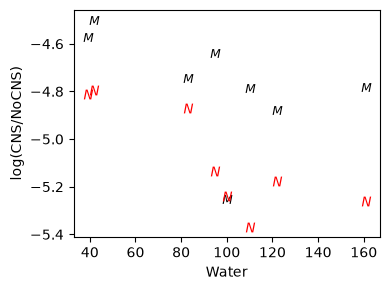

In [13]:
# Visualize dataset
print(df['Work'].cat.categories)
plt.figure(figsize=(4, 3))
markers = {'Manual': r'$M$', 'NonManual': r'$N$'}
colors = {'Manual': 'black', 'NonManual': 'red'}

for work_val, group in df.groupby('Work'):
    # plt.scatter(group['Water'], logit(group['prop']),
    plt.scatter(group['Water'], logit(group['odds']),
        marker=markers[work_val], color=colors[work_val], linewidths=0, s=50)

plt.xlabel('Water')
plt.ylabel('log(CNS/NoCNS)')
plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'cns_prop.pdf')
# plt.savefig(fig_path, bbox_inches="tight")

In [14]:
print(df.iloc[:, [0, 5]] )

             Area  Water
1         Cardiff    110
2         Newport    100
3         Swansea     95
4      GlamorganE     42
5      GlamorganW     39
6      GlamorganC    161
7       MonmouthV     83
8   MonmouthOther    122
9         Cardiff    110
10        Newport    100
11        Swansea     95
12     GlamorganE     42
13     GlamorganW     39
14     GlamorganC    161
15      MonmouthV     83
16  MonmouthOther    122


In [15]:
# Fit logistic regression models
fm1 = glm('CNS + NoCNS ~ Work + Water', df, family=Binomial()).fit()
fm2 = glm('CNS + NoCNS ~ Work + Area', df, family=Binomial()).fit()

# view X matrix
print(fm1.model.exog, '\n')
print(fm2.model.exog, '\n')

[[  1.   1. 110.]
 [  1.   1. 100.]
 [  1.   1.  95.]
 [  1.   1.  42.]
 [  1.   1.  39.]
 [  1.   1. 161.]
 [  1.   1.  83.]
 [  1.   1. 122.]
 [  1.   0. 110.]
 [  1.   0. 100.]
 [  1.   0.  95.]
 [  1.   0.  42.]
 [  1.   0.  39.]
 [  1.   0. 161.]
 [  1.   0.  83.]
 [  1.   0. 122.]] 

[[1. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 0. 0. 0. 1. 0.]
 [1. 1. 0. 0. 0. 0. 0. 0. 1.]
 [1. 1. 0. 1. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 0. 0. 1. 0. 0.]
 [1. 1. 0. 0. 0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0.]] 



In [16]:
# Compare nested models, fm1 and fm2
print(anova_nested(fm1, fm2), '\n')

# test whether any term can be dropped from fm1
print(drop1_glm(fm1), '\n')

# test whether interaction term is significant
fm1a = update_glm(fm1, add='Water:Work')
print(anova_nested(fm1, fm1a), '\n')

# test whether higher order term in Water is siginificant
fm1b = update_glm(fm1, add='I(Water**2)')
print(anova_nested(fm1, fm1b), '\n')

# Goodness of fit of fm1
chi2.sf(fm1.deviance, fm1.df_resid)

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1       13.0   12.362813  NaN       NaN       NaN
Model 2        7.0    3.077120  6.0  9.285694  0.158137 

       Df   Deviance         AIC        LRT  Pr(>Chi)
<none>     12.362813  102.489073                     
Work    1  25.358655  113.484915  12.995842  0.000312
Water   1  23.908757  112.035016  11.545943  0.000679 

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1       13.0   12.362813  NaN       NaN       NaN
Model 2       12.0   11.937716  1.0  0.425098  0.514404 

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1       13.0   12.362813  NaN       NaN       NaN
Model 2       12.0    9.366322  1.0  2.996492  0.083445 



np.float64(0.49814104873208154)

Text(0, 0.5, 'log(CNS/NoCNS)')

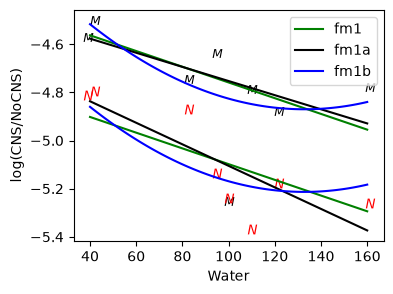

In [17]:
# Prediction
water_values = np.linspace(40, 160, 100)
df_pred_M = pd.DataFrame({'Water': water_values, 'Work': 'Manual'})
df_pred_N = pd.DataFrame({'Water': water_values, 'Work': 'NonManual'})

plt.figure(figsize=(4, 3))
markers = {'Manual': r'$M$', 'NonManual': r'$N$'}
colors = {'Manual': 'black', 'NonManual': 'red'}

for work_val, group in df.groupby('Work'):
    plt.scatter(group['Water'], logit(group['odds']),
        marker=markers[work_val], color=colors[work_val], linewidths=0, s=50)

# Water + Work
plt.plot(water_values, fm1.predict(df_pred_M, which='linear'), color='green', label='fm1')
plt.plot(water_values, fm1.predict(df_pred_N, which='linear'), color='green')

# Water*Work
plt.plot(water_values, fm1a.predict(df_pred_M, which='linear'), color='black', label='fm1a')
plt.plot(water_values, fm1a.predict(df_pred_N, which='linear'), color='black')

# Water + Water^2 + Work
plt.plot(water_values, fm1b.predict(df_pred_M, which='linear'), color='blue', label='fm1b')
plt.plot(water_values, fm1b.predict(df_pred_N, which='linear'), color='blue')

plt.legend()
plt.xlabel('Water')
plt.ylabel('log(CNS/NoCNS)')

# fig_path = os.path.join(fig_save_dir, 'cns_fitted.pdf')
# plt.savefig(fig_path, bbox_inches="tight")

In [18]:
# Interpret model
print(fm1.params)
print(np.exp(fm1.params))

Intercept           -4.432580
Work[T.NonManual]   -0.339058
Water               -0.003264
dtype: float64
Intercept            0.011884
Work[T.NonManual]    0.712441
Water                0.996741
dtype: float64


In [19]:
# Convert data to one row for each predictor setting with a count
df_cnts = df.melt(id_vars=['Area', 'Water', 'Work'], value_vars=['An', 'Sp', 'Other'], var_name='Status', value_name='count')
df_cnts['Status'] = pd.Categorical(df_cnts['Status'], categories=['An', 'Sp', 'Other'], ordered=True)
print(df_cnts.info())

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   Area    48 non-null     category
 1   Water   48 non-null     int64   
 2   Work    48 non-null     category
 3   Status  48 non-null     category
 4   count   48 non-null     int64   
dtypes: category(3), int64(2)
memory usage: 1.2 KB
None


In [20]:
df_long = df_cnts.loc[df_cnts.index.repeat(df_cnts['count'])].reset_index(drop=True)
df_long = df_long.drop(columns=['count'])
print(df_long.head())
y = df_long['Status'].cat.codes

      Area  Water       Work Status
0  Cardiff    110  NonManual     An
1  Cardiff    110  NonManual     An
2  Cardiff    110  NonManual     An
3  Cardiff    110  NonManual     An
4  Cardiff    110  NonManual     An


In [21]:
# Water * Work
X = patsy.dmatrix('Water * Work', df_long, return_type='dataframe')
fm3 = MNLogit(y, X).fit()
drop1_MNL(fm3, X)

Optimization terminated successfully.
         Current function value: 0.987685
         Iterations 6


,Dropped,Df,Deviance,AIC,LRT,Pr(>Chi)
0,<none>,,1370.907394,1386.907394,,
1,Water:Work,2.0,1371.524475,1383.524475,0.617081,0.734518


In [22]:
# Water + Work
X = patsy.dmatrix('Water + Work', df_long, return_type='dataframe')
fm3 = MNLogit(y, X).fit()
drop1_MNL(fm3, X)

Optimization terminated successfully.
         Current function value: 0.988130
         Iterations 6


,Dropped,Df,Deviance,AIC,LRT,Pr(>Chi)
0,<none>,,1371.524475,1383.524475,,
1,Work,2.0,1373.161112,1381.161112,1.636637,0.441173
2,Water,2.0,1373.124119,1381.124119,1.599644,0.449409


In [23]:
# Work
X = patsy.dmatrix('Work', df_long, return_type='dataframe')
fm3 = MNLogit(y, X).fit()
drop1_MNL(fm3, X)

Optimization terminated successfully.
         Current function value: 0.989283
         Iterations 6


,Dropped,Df,Deviance,AIC,LRT,Pr(>Chi)
0,<none>,,1373.124119,1381.124119,,
1,Work,2.0,1374.454833,1378.454833,1.330714,0.51409


In [24]:
# Null model
fm3 = MNLogit(y, X.iloc[:, 0]).fit()
print(fm3.predict(pd.DataFrame({'const': [1]})))

# overall fitted proportions
overall_prop = df[['An', 'Sp', 'Other']].sum(axis=0) / df[['An', 'Sp', 'Other']].values.sum()
print(overall_prop)

Optimization terminated successfully.
         Current function value: 0.990241
         Iterations 5
          0         1         2
0  0.368876  0.492795  0.138329
An       0.368876
Sp       0.492795
Other    0.138329
dtype: float64


In [25]:
# Convert data to one row for each predictor setting with a count
df_cnts = df.melt(id_vars=['Area', 'Water', 'Work'], value_vars=['NoCNS', 'An', 'Sp', 'Other'], var_name='Status', value_name='count')
df_cnts['Status'] = pd.Categorical(df_cnts['Status'], categories=['NoCNS', 'An', 'Sp', 'Other'], ordered=True)

In [26]:
df_long = df_cnts.loc[df_cnts.index.repeat(df_cnts['count'])].reset_index(drop=True)
df_long = df_long.drop(columns=['count'])
print(df_long.head())
y = df_long['Status'].cat.codes

      Area  Water       Work Status
0  Cardiff    110  NonManual  NoCNS
1  Cardiff    110  NonManual  NoCNS
2  Cardiff    110  NonManual  NoCNS
3  Cardiff    110  NonManual  NoCNS
4  Cardiff    110  NonManual  NoCNS


In [27]:
# Water * Work
X = patsy.dmatrix('Water * Work', df_long, return_type='dataframe')
fm4 = MNLogit(y, X).fit()
drop1_MNL(fm4, X)

Optimization terminated successfully.
         Current function value: 0.055530
         Iterations 10


,Dropped,Df,Deviance,AIC,LRT,Pr(>Chi)
0,<none>,,9389.958098,9413.958098,,
1,Water:Work,3.0,9390.965193,9408.965193,1.007095,0.799535


In [28]:
# Water + Work
X = patsy.dmatrix('Water + Work', df_long, return_type='dataframe')
fm4 = MNLogit(y, X).fit()
drop1_MNL(fm4, X)

Optimization terminated successfully.
         Current function value: 0.055536
         Iterations 9


,Dropped,Df,Deviance,AIC,LRT,Pr(>Chi)
0,<none>,,9390.965193,9408.965193,,
1,Work,3.0,9405.707628,9417.707628,14.742435,0.002051
2,Water,3.0,9404.302218,9416.302218,13.337025,0.003962


In [29]:
print(fm4.summary2())

                         Results: MNLogit
Model:               MNLogit          Method:           MLE       
Dependent Variable:  y                Pseudo R-squared: 0.003     
Date:                2026-10-26 10:48 AIC:              9408.9652 
No. Observations:    84549            BIC:              9493.0710 
Df Model:            6                Log-Likelihood:   -4695.5   
Df Residuals:        84540            LL-Null:          -4711.4   
Converged:           1.0000           LLR p-value:      1.7772e-05
No. Iterations:      9.0000           Scale:            1.0000    
------------------------------------------------------------------
      y = 0        Coef.  Std.Err.    t     P>|t|   [0.025  0.975]
------------------------------------------------------------------
        Intercept -5.4551   0.1478 -36.9086 0.0000 -5.7448 -5.1655
Work[T.NonManual] -0.3639   0.1605  -2.2671 0.0234 -0.6784 -0.0493
            Water -0.0029   0.0016  -1.8337 0.0667 -0.0060  0.0002
--------------------